In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import f_oneway, pearsonr
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error, accuracy_score
from pmdarima import auto_arima
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
import warnings
warnings.filterwarnings("ignore")

df = pd.read_csv('CarSharing.csv')

df = df.drop_duplicates()
print(df.isnull().sum())

df['temp'].fillna(df['temp'].mean(), inplace=True)  
df['humidity'].fillna(df['humidity'].median(), inplace=True) 
df['windspeed'].fillna(df['windspeed'].mean(), inplace=True)  
df['demand'].fillna(df['demand'].mean(), inplace=True)  

df.to_csv('Cleaned_Dataset.csv', index=False)

id            0
timestamp     0
season        0
holiday       0
workingday    0
weather       0
temp          0
temp_feel     0
humidity      0
windspeed     0
demand        0
dtype: int64


In [29]:
def anova_test(df, categorical_col, target_col):
    groups = [df[df[categorical_col] == group][target_col] for group in df[categorical_col].unique()]
    f_stat, p_value = f_oneway(*groups)
    return p_value

def pearson_test(df, numerical_col, target_col):
    corr, p_value = pearsonr(df[numerical_col], df[target_col])
    return p_value

categorical_cols = ['season', 'holiday', 'workingday', 'weather']
numerical_cols = ['temp', 'temp_feel', 'humidity', 'windspeed']

results = {}
for col in categorical_cols:
    p_value = anova_test(df, col, 'demand')
    results[col] = p_value

for col in numerical_cols:
    p_value = pearson_test(df, col, 'demand')
    results[col] = p_value

for col, p_value in results.items():
    print(f"{col}: p-value = {p_value}")

season: p-value = 8.024921568562112e-95
holiday: p-value = 0.9162670761960895
workingday: p-value = 0.09037224773166397
weather: p-value = 3.9279297308870713e-31
temp: p-value = 3.572519929407108e-279
temp_feel: p-value = 5.96404385e-315
humidity: p-value = 2.1447286875535288e-221
windspeed: p-value = 1.6061463000774494e-28


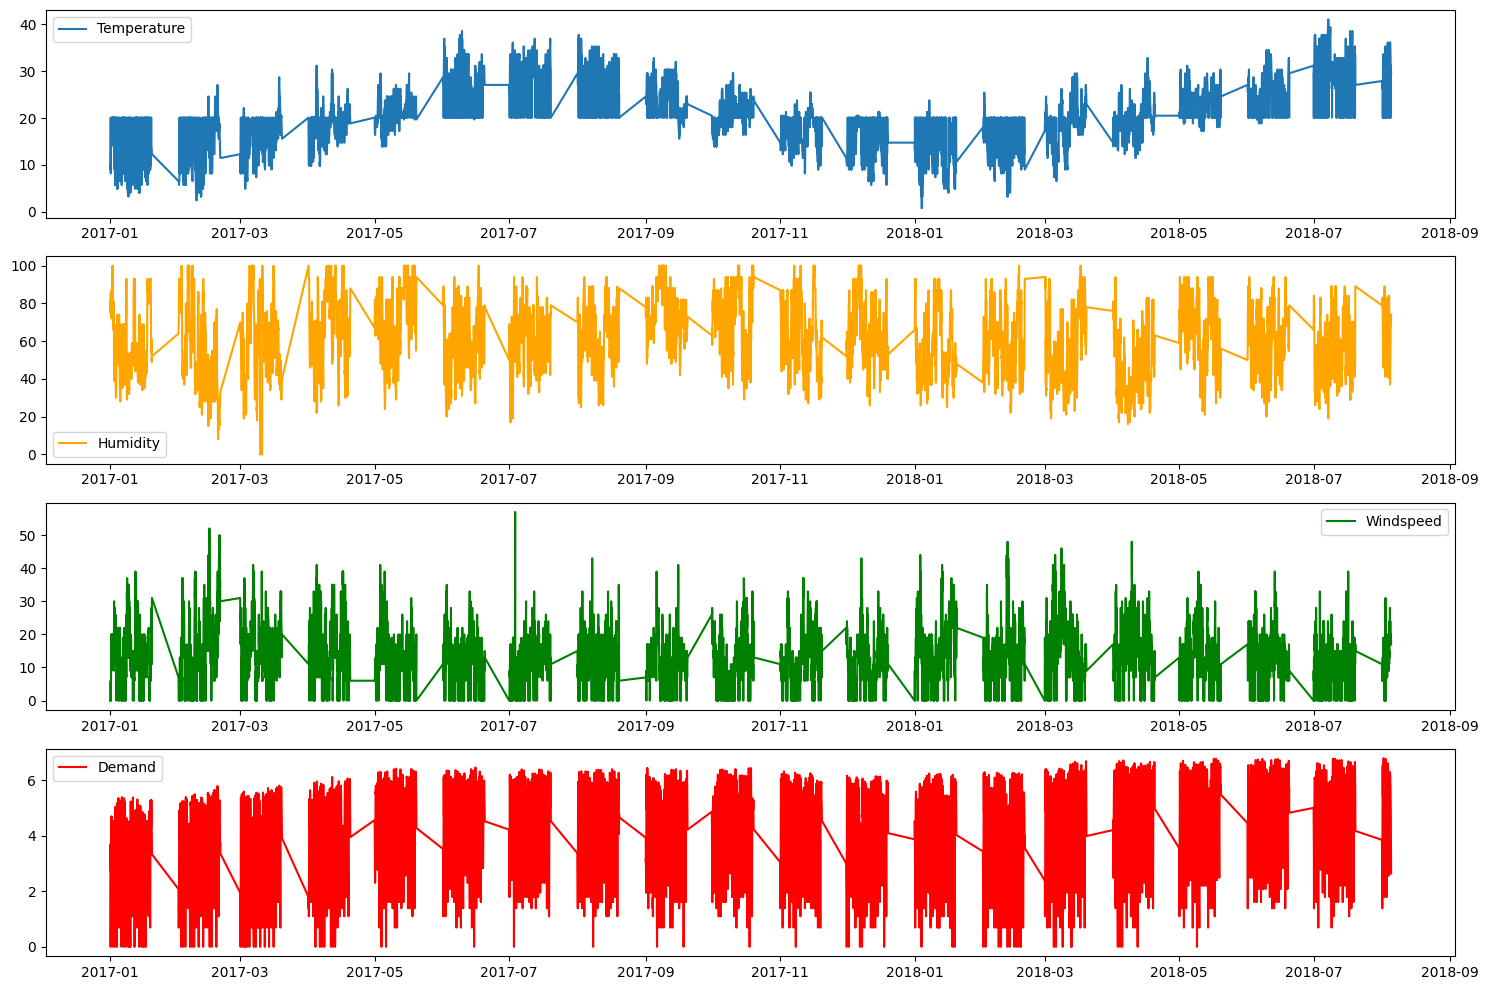

In [30]:
df['timestamp'] = pd.to_datetime(df['timestamp'])

plt.figure(figsize=(15, 10))
plt.subplot(4, 1, 1)
plt.plot(df['timestamp'], df['temp'], label='Temperature')
plt.legend()

plt.subplot(4, 1, 2)
plt.plot(df['timestamp'], df['humidity'], label='Humidity', color='orange')
plt.legend()

plt.subplot(4, 1, 3)
plt.plot(df['timestamp'], df['windspeed'], label='Windspeed', color='green')
plt.legend()

plt.subplot(4, 1, 4)
plt.plot(df['timestamp'], df['demand'], label='Demand', color='red')
plt.legend()

plt.tight_layout()
plt.show()

In [32]:
df_weekly = df.resample('W', on='timestamp').mean()

df_weekly.fillna(df_weekly.mean(), inplace=True)

train_size = int(len(df_weekly) * 0.7)
train, test = df_weekly[:train_size], df_weekly[train_size:]

auto_model = auto_arima(train['demand'], seasonal=False, trace=True, error_action='ignore', suppress_warnings=True)

model = ARIMA(train['demand'], order=auto_model.order)
model_fit = model.fit()

predictions = model_fit.forecast(steps=len(test))

mse = mean_squared_error(test['demand'], predictions)
print(f"ARIMA Model MSE: {mse}")

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=13.187, Time=1.31 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=35.352, Time=0.04 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=27.198, Time=0.05 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=16.660, Time=0.38 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=33.634, Time=0.02 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=12.838, Time=2.32 sec
 ARIMA(0,1,2)(0,0,0)[0] intercept   : AIC=17.987, Time=0.74 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=18.483, Time=1.10 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : AIC=13.633, Time=1.26 sec
 ARIMA(0,1,3)(0,0,0)[0] intercept   : AIC=12.177, Time=0.44 sec
 ARIMA(0,1,4)(0,0,0)[0] intercept   : AIC=13.013, Time=0.44 sec
 ARIMA(1,1,4)(0,0,0)[0] intercept   : AIC=13.593, Time=1.31 sec
 ARIMA(0,1,3)(0,0,0)[0]             : AIC=11.843, Time=0.49 sec
 ARIMA(0,1,2)(0,0,0)[0]             : AIC=17.751, Time=0.19 sec
 ARIMA(1,1,3)(0,0,0)[0]             : AIC=13.179, Time=0.45 s

In [34]:
X = df[['temp', 'humidity', 'windspeed']]
y = df['demand']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print("Random Forest Regressor")
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
rf_mse = mean_squared_error(y_test, rf_pred)
print(f"MSE: {rf_mse}")

print("\nDeep Neural Network")
model = Sequential()
model.add(Dense(64, input_dim=3, activation='relu'))
model.add(Dense(32, activation='relu'))
model.add(Dense(1))
model.compile(optimizer='adam', loss='mean_squared_error')
model.fit(X_train, y_train, epochs=50, batch_size=32, verbose=0)
nn_pred = model.predict(X_test)
nn_mse = mean_squared_error(y_test, nn_pred)
print(f"MSE: {nn_mse}")

Random Forest Regressor
MSE: 1.95548233592596

Deep Neural Network
82/82 [==============================] - 0s 874us/step
MSE: 1.653056567515597


In [35]:
df['demand_label'] = df['demand'].apply(lambda x: 1 if x > df['demand'].mean() else 2)

X = df[['temp', 'humidity', 'windspeed']]
y = df['demand_label']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print("Accuracy Comparison\n")
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
rf_acc = accuracy_score(y_test, rf.predict(X_test))
print(f"For the random forest classifier, it is {rf_acc}")

svm = SVC(random_state=42)
svm.fit(X_train, y_train)
svm_acc = accuracy_score(y_test, svm.predict(X_test))
print(f"For the SVM classifier, it is {svm_acc}")

knn = KNeighborsClassifier()
knn.fit(X_train, y_train)
knn_acc = accuracy_score(y_test, knn.predict(X_test))
print(f"For the KNN classifier, it is {knn_acc}")

Accuracy Comparison

For the random forest classifier, it is 0.6769996172981247
For the SVM classifier, it is 0.7263681592039801
For the KNN classifier, it is 0.6930730960581707


In [36]:
X = df[['temp']]

k_values = [2, 3, 4, 12]
print("K-MEANS CLUSTERING")
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X)
    labels = kmeans.labels_
    cluster_counts = np.bincount(labels)
    print(f"When k is {k}, the cluster counts are {cluster_counts}")

print("\nAGGLOMERATIVE CLUSTERING")
for k in k_values:
    agg = AgglomerativeClustering(n_clusters=k)
    labels = agg.fit_predict(X)
    cluster_counts = np.bincount(labels)
    print(f"When k is {k}, the cluster counts are {cluster_counts}")

K-MEANS CLUSTERING
When k is 2, the cluster counts are [3347 5361]
When k is 3, the cluster counts are [2666 3633 2409]
When k is 4, the cluster counts are [2666 1526 1259 3257]
When k is 12, the cluster counts are [ 441  909 1120  947  479  992  365 1558  334   92  823  648]

AGGLOMERATIVE CLUSTERING
When k is 2, the cluster counts are [5923 2785]
When k is 3, the cluster counts are [2785 2394 3529]
When k is 4, the cluster counts are [2394 1972 3529  813]
When k is 12, the cluster counts are [ 525  859  915 1010  752  611  811  567 1558  202  408  490]
